# Medical Imaging × Glitch Art — Data Prep

One notebook for all the images:

1. Download the 2 Kaggle datasets + the glitch art from the catalog
2. Load a sample: resize to 128 x 128, keep grayscale pixels (like the faces)
3. Look: examples, sizes, average image per group
4. Simple features: brightness, contrast, colourfulness
5. A self-made glitch
6. First look with PCA
7. Save

## Setup

In [2]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py

!pip install -q kagglehub
!mkdir -p data/glitch data/small data/clean


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import PIL.Image as PImage

from sklearn.decomposition import PCA

from image_utils import get_pixels, make_image

import kagglehub

SMALL = 128

/usr/local/python/3.14.2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
# 1. Download

In [4]:
ct_path = kagglehub.dataset_download("shuvokumarbasakbd/brain-ct-medical-imaging-colorized-dataset")
tumor_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

CT_PATH = ct_path + "/Computed Tomography (CT) of the Brain/dataset/train/"
MRI_PATH = tumor_path + "/Training/"

print(os.listdir(CT_PATH))
print(os.listdir(MRI_PATH))

100%|██████████| 93.1M/93.1M [00:01<00:00, 91.5MB/s]

Extracting files...


100%|██████████| 157M/157M [00:00<00:00, 201MB/s]  

Extracting files...


['aneurysm', 'tumor', 'cancer']
['pituitary', 'glioma', 'notumor', 'meningioma']


In [5]:
catalog_df = pd.read_csv("data/glitch/glitch_credits.csv").fillna("")

for f, url in zip(catalog_df["file"], catalog_df["image_url"]):
  if url != "" and not os.path.exists("data/glitch/" + f):
    !wget -q "{url}" -O "data/glitch/{f}"

missing = []
for f, title in zip(catalog_df["file"], catalog_df["title"]):
  if not os.path.exists("data/glitch/" + f) or os.path.getsize("data/glitch/" + f) == 0:
    missing.append(title)

print(len(catalog_df) - len(missing), "of", len(catalog_df), "catalog works have an image")
print("still need a screenshot / still:", missing)

/tmp/ipykernel_15413/240579075.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  catalog_df = pd.read_csv("data/glitch/glitch_credits.csv").fillna("")


30 of 51 catalog works have an image
still need a screenshot / still: ['Glitchometry', 'Dither Studies', 'TIME IS NEVER WAS NEVER IS TIME', 'NES Glitch Compilation', 'flo\\/\\/', 'System Landscapes', '8 BIT WEB', 'Data Diaries', 'Bomb Iraq', 'ppt.xxx', '00FFFF - Pixelation Routine', 'Monogrid 0.1', 'troika', 'Nowash', 'Selbst-los / Self-less', 'Pscan Derivatives', 'liquid_eden', 'IPicons', 'Recombinant Icon', 'Illicit images', 'ap0202']


---
# 2. Load a Sample

40 per medical label is plenty for data prep.

In [6]:
PER_LABEL = 40

to_load = []

for dataset, base in [("brain_ct", CT_PATH), ("brain_mri", MRI_PATH)]:
  for label in sorted(os.listdir(base)):
    files = sorted(os.listdir(base + label))
    for f in files[:PER_LABEL]:
      to_load.append((dataset, label, base + label + "/" + f))

for f, site in zip(catalog_df["file"], catalog_df["source_site"]):
  if os.path.exists("data/glitch/" + f) and os.path.getsize("data/glitch/" + f) > 0:
    to_load.append(("glitch_art", site, "data/glitch/" + f))

print(len(to_load), "images to load")

310 images to load


Load each one, like the faces notebook:

- remember the **original** size and colour mode (`L` = grayscale, `RGB` = colour)
- resize to 128 x 128 (GIFs: `open()` gives the first frame)
- keep RGB pixels (for colour) and grayscale pixels (for PCA)
- save a small PNG copy

In [7]:
rows = []
rgb_pixels = []
gray_pixels = []

for dataset, label, path in to_load:
  mimg = PImage.open(path)

  rows.append({
    "dataset": dataset,
    "label": label,
    "file": path.split("/")[-1],
    "orig_width": mimg.size[0],
    "orig_height": mimg.size[1],
    "orig_mode": mimg.mode,
  })

  small = mimg.convert("RGB").resize((SMALL, SMALL))
  small.save("data/small/" + dataset + "_" + str(len(rows)) + ".png")

  rgb_pixels.append(get_pixels(small))
  gray_pixels.append(get_pixels(small.convert("L")))

images_df = pd.DataFrame(rows)
gray_df = pd.DataFrame(gray_pixels)

print(images_df.shape, gray_df.shape)
images_df[["dataset", "label"]].value_counts().sort_index()

(310, 6) (310, 16384)


dataset     label         
brain_ct    aneurysm          40
            cancer            40
            tumor             40
brain_mri   glioma            40
            meningioma        40
            notumor           40
            pituitary         40
glitch_art  Glitch Gallery    30
Name: count, dtype: int64

---
# 3. Look

### Original sizes and colour modes

In [8]:
for dataset in images_df["dataset"].unique():
  ds_df = images_df[images_df["dataset"] == dataset]
  print("=====", dataset)
  print(ds_df["orig_mode"].value_counts())
  display(ds_df[["orig_width", "orig_height"]].describe().round(0))

===== brain_ct
orig_mode
RGB    120
Name: count, dtype: int64


,orig_width,orig_height
count,120.0,120.0
mean,512.0,512.0
std,0.0,0.0
min,512.0,512.0
25%,512.0,512.0
50%,512.0,512.0
75%,512.0,512.0
max,512.0,512.0


===== brain_mri
orig_mode
RGB    102
L       58
Name: count, dtype: int64


,orig_width,orig_height
count,160.0,160.0
mean,467.0,465.0
std,116.0,112.0
min,192.0,183.0
25%,512.0,512.0
50%,512.0,512.0
75%,512.0,512.0
max,900.0,741.0


===== glitch_art
orig_mode
RGB     20
RGBA     7
P        3
Name: count, dtype: int64


,orig_width,orig_height
count,30.0,30.0
mean,1295.0,978.0
std,675.0,659.0
min,250.0,220.0
25%,890.0,583.0
50%,1024.0,800.0
75%,1659.0,1070.0
max,2881.0,3456.0


### 4 examples from each group

brain_ct / aneurysm


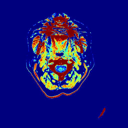

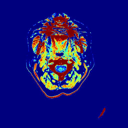

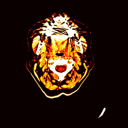

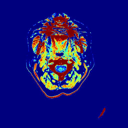

brain_ct / cancer


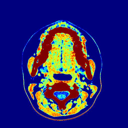

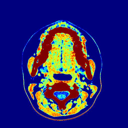

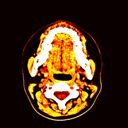

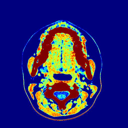

brain_ct / tumor


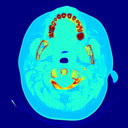

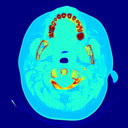

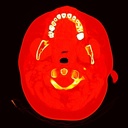

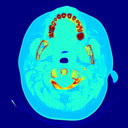

brain_mri / glioma


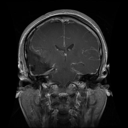

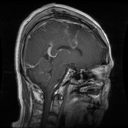

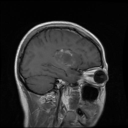

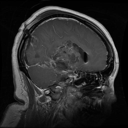

brain_mri / meningioma


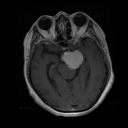

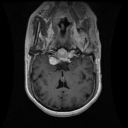

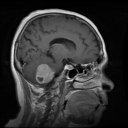

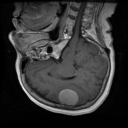

brain_mri / notumor


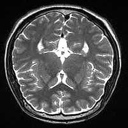

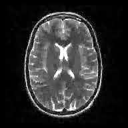

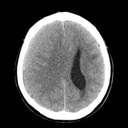

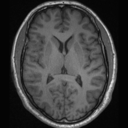

brain_mri / pituitary


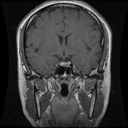

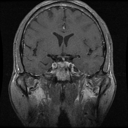

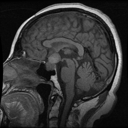

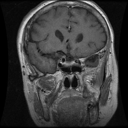

glitch_art / Glitch Gallery


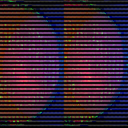

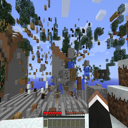

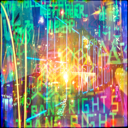

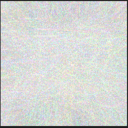

In [9]:
groups = images_df[["dataset", "label"]].drop_duplicates().values

for dataset, label in groups:
  idxs = images_df[(images_df["dataset"] == dataset) & (images_df["label"] == label)].index[:4]
  print(dataset, "/", label)
  for i in idxs:
    display(make_image(rgb_pixels[i], width=SMALL))

### Average image per group

Average each pixel column over a group's images (like the "most average face").

brain_ct / aneurysm - 40 images


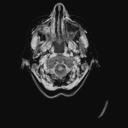

brain_ct / cancer - 40 images


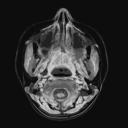

brain_ct / tumor - 40 images


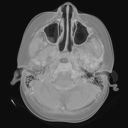

brain_mri / glioma - 40 images


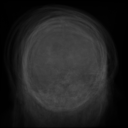

brain_mri / meningioma - 40 images


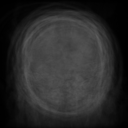

brain_mri / notumor - 40 images


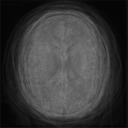

brain_mri / pituitary - 40 images


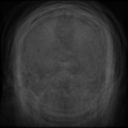

glitch_art / Glitch Gallery - 30 images


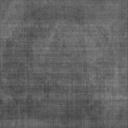

In [10]:
for dataset, label in groups:
  mask = ((images_df["dataset"] == dataset) & (images_df["label"] == label)).values
  print(dataset, "/", label, "-", mask.sum(), "images")
  display(make_image(gray_df[mask].mean(), width=SMALL))

---
# 4. Simple Features

| feature | how |
|---|---|
| `brightness` | average gray value |
| `contrast` | spread (standard deviation) of gray values |
| `colourfulness` | average of (biggest − smallest of R, G, B) per pixel → 0 for a gray image |

In [11]:
brightness = []
contrast = []
colourfulness = []

for i in range(len(images_df)):
  g = pd.Series(gray_pixels[i])
  brightness.append(g.mean())
  contrast.append(g.std())

  rgb_df = pd.DataFrame(rgb_pixels[i], columns=["R", "G", "B"])
  colourfulness.append((rgb_df.max(axis=1) - rgb_df.min(axis=1)).mean())

images_df["brightness"] = brightness
images_df["contrast"] = contrast
images_df["colourfulness"] = colourfulness

for dataset in images_df["dataset"].unique():
  ds_df = images_df[images_df["dataset"] == dataset]
  print(dataset, " brightness:", round(ds_df["brightness"].mean(), 1),
        " contrast:", round(ds_df["contrast"].mean(), 1),
        " colourfulness:", round(ds_df["colourfulness"].mean(), 1))

brain_ct  brightness: 54.7  contrast: 60.7  colourfulness: 128.7
brain_mri  brightness: 46.1  contrast: 44.8  colourfulness: 0.0
glitch_art  brightness: 99.5  contrast: 48.2  colourfulness: 60.3


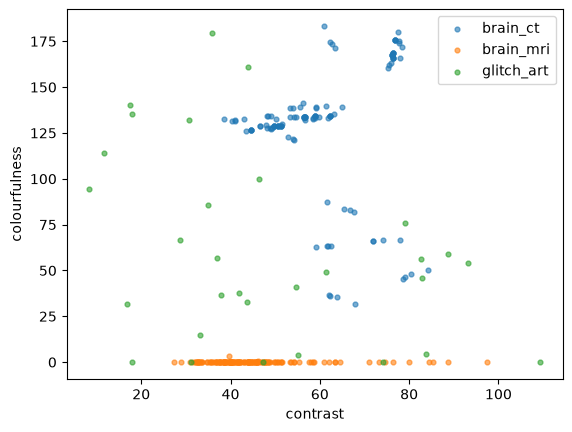

In [12]:
for dataset in images_df["dataset"].unique():
  ds_df = images_df[images_df["dataset"] == dataset]
  plt.scatter(ds_df["contrast"], ds_df["colourfulness"], s=12, alpha=0.6, label=dataset)

plt.xlabel("contrast")
plt.ylabel("colourfulness")
plt.legend()
plt.show()

---
# 5. Self-Made Glitch

Row `y` of a 128-wide image = pixels `y*128` to `y*128 + 128`. For rows 40–70, move the last 25 pixels of each row to the front (a sideways shift).

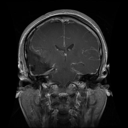

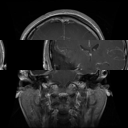

In [13]:
mri_idx = images_df[images_df["dataset"] == "brain_mri"].index[0]
original = rgb_pixels[mri_idx]

glitched = list(original)
for y in range(40, 70):
  start = y * SMALL
  row = original[start : start + SMALL]
  glitched[start : start + SMALL] = row[-25:] + row[:-25]

display(make_image(original, width=SMALL))
display(make_image(glitched, width=SMALL))

---
# 6. First Look with PCA

PCA on the grayscale pixels, coloured by group.

explained variance: 0.7638859747473249


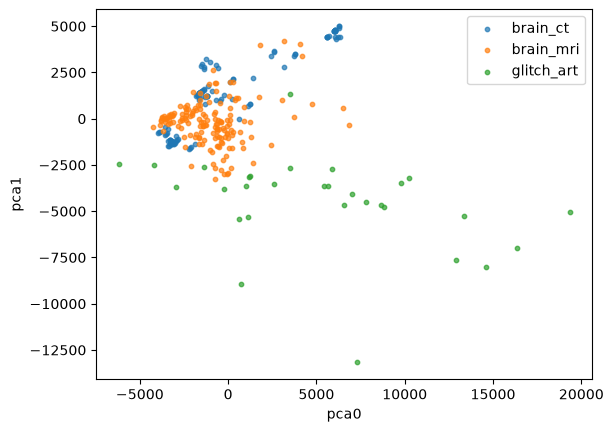

In [14]:
pca = PCA(n_components=20).set_output(transform="pandas")
pca_df = pca.fit_transform(gray_df)

print("explained variance:", sum(pca.explained_variance_ratio_))

for dataset in images_df["dataset"].unique():
  mask = (images_df["dataset"] == dataset).values
  plt.scatter(pca_df["pca0"][mask], pca_df["pca1"][mask], s=10, alpha=0.7, label=dataset)
plt.xlabel("pca0")
plt.ylabel("pca1")
plt.legend()
plt.show()

The first 4 components as images:

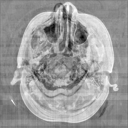

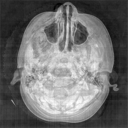

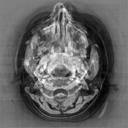

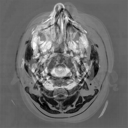

In [15]:
for comp in pca.components_[:4]:
  minVal = comp.min()
  maxVal = comp.max()
  pxs = 255 * (comp - minVal) / (maxVal - minVal)
  display(make_image(pxs, width=SMALL))

---
# 7. Saving

In [16]:
images_df.to_csv("data/clean/image_features.csv", index=False)
print(images_df.shape)

(310, 9)


---
# Plan

| Question | Method (week) |
|---|---|
| What do medical images and glitch art share visually? | features + KMeans + silhouette |
| Does organizing by resemblance cut across labels? | PCA / t-SNE coloured by label |
| Intentional vs. accidental distortion | self-made glitches; catalog text (`glitch_catalog_text.ipynb`) |
| Later | neural image features (wk 12–14) |

**Limitations:** the Kaggle scans are mostly clean (few real artifacts); similar look ≠ same process; resizing is a distortion I add; glitch art is hand-picked.

**Sources:** Brain CT Medical Imaging Colorized Dataset (Kaggle) · Brain Tumor MRI Dataset (Kaggle) · Glitch Gallery · Rhizome ArtBase